# AeroTrack — Part 7: Re-Identification (fixed: camera-compensated, spatially gated, lower thresholds)

**What changed**
- Crop filters relaxed: people in drone footage are tiny, and the old limits (>=20x40 px, >=5 observations) silently excluded many tracklets from ReID. Each excluded tracklet then counted as a new person.
- More crops per tracklet (8), small crops are upscaled before OSNet.
- **Spatio-temporal gating** using `world_x/world_y` from Part 1: a pair whose positions are impossible given the time gap is never a candidate; a pair that is close in space and time gets a bounded bonus (max 0.10) added to the OSNet cosine score. `appearance_similarity` keeps the raw OSNet score; `multi_mean_similarity` is the fused score that Parts 9-10 threshold.
- Thresholds lowered: auto-link 0.72, review 0.65, margin 0.015.

Treat all Global IDs as provisional and review merged groups.



## Objective

This notebook processes the active video selected in Part 1. It loads the detailed tracking log, selects representative crops, extracts OSNet appearance embeddings, compares non-overlapping tracklets from the same video, and exports provisional Global IDs and candidate matches.

Part 11 and multiple videos are not required.


## Section 1 — Project paths and active video

Run Part 1 first. It writes `outputs/active_video_config.json`. Part 7 reads that file, so you only need to choose the video in Part 1. Keep the original video and detailed tracking log together in the AeroTrack project.

In [1]:
from pathlib import Path
import time
import math
import json
import hashlib

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import sys
sys.path.insert(0, str(Path.cwd()))
import aerotrack_utils as U

from IPython.display import display, Video

try:
    from reid import ReIDModel
except ImportError as exc:
    raise ImportError(
        "Part 7 requires the existing 'reid' package that provides ReIDModel. "
        "This is not torchreid. Use the Python environment from your earlier "
        "OSNet/ReID experiment; do not reinstall PyTorch or CUDA just for this notebook."
    ) from exc

PROJECT_DIR = Path.cwd().resolve()
DATA_DIR = PROJECT_DIR / "data"
OUTPUT_DIR = PROJECT_DIR / "outputs"

ACTIVE_VIDEO_CONFIG_PATH = OUTPUT_DIR / "active_video_config.json"
if not ACTIVE_VIDEO_CONFIG_PATH.exists():
    raise FileNotFoundError(
        f"Missing {ACTIVE_VIDEO_CONFIG_PATH}. Run Part 1 before Part 7."
    )
with open(ACTIVE_VIDEO_CONFIG_PATH, "r", encoding="utf-8") as file:
    ACTIVE_VIDEO_CONFIG = json.load(file)

VIDEO_ID = str(ACTIVE_VIDEO_CONFIG["video_id"])
VIDEO_OUTPUT_DIR = OUTPUT_DIR / VIDEO_ID
VIDEO_PATH = PROJECT_DIR / ACTIVE_VIDEO_CONFIG["video_path"]
TRACK_LOG_PATH = PROJECT_DIR / ACTIVE_VIDEO_CONFIG["track_log_path"]
SEGMENT_START_SECONDS = float(ACTIVE_VIDEO_CONFIG.get("segment_start_seconds", 0.0))

PART7_DIR = VIDEO_OUTPUT_DIR / "part7_global_identity"
CROP_DIR = PART7_DIR / "tracklet_crops"
PART7_DIR.mkdir(parents=True, exist_ok=True)
CROP_DIR.mkdir(parents=True, exist_ok=True)

VIDEO_SOURCES = [{
    "video_id": VIDEO_ID,
    "video_path": VIDEO_PATH,
    "track_log_path": TRACK_LOG_PATH,
    "segment_start_seconds": SEGMENT_START_SECONDS
}]

# Crop selection.
MIN_CONFIDENCE = 0.20
MIN_BOX_WIDTH = 8
MIN_BOX_HEIGHT = 18
MIN_TRACK_OBSERVATIONS = 3
MAX_CROPS_PER_TRACKLET = 8
CROP_MARGIN_RATIO = 0.08
MIN_CROP_HEIGHT_FOR_REID = 128   # tiny crops are upscaled (cubic) before OSNet

# The pretrained OSNet implementation used in the earlier ReID notebooks.
REID_MODEL_NAME = "osnet_x1_0_msmt17_combineall"
EMBEDDING_BATCH_SIZE = 8

# Experimental lower-threshold profile for this controlled comparison.
# Similarity values are cosine scores, not probabilities. Mutual-best, margin,
# and same-video temporal-overlap safeguards remain enabled. Inspect new merges.
AUTO_LINK_THRESHOLD = 0.72
REVIEW_THRESHOLD = 0.65
MIN_SIMILARITY_MARGIN = 0.015
ENABLE_PROVISIONAL_AUTO_LINKS = True

# False disables only cross-video matching. Same-video non-overlapping
# tracklets remain eligible and are the focus of this experiment.
ENABLE_CROSS_VIDEO_MATCHING = False

# Camera-compensated spatial gating (needs world_x/world_y/world_h from Part 1).
USE_SPATIAL_GATING = True
SPATIAL_CFG = U.SpatialConfig(
    max_bonus=0.10,                 # most the position can add to the OSNet score
    max_speed_heights_per_sec=2.5,  # running speed in body heights/s
    long_gap_seconds=8.0            # beyond this, position is not used
)

print("Active video:", VIDEO_ID)
print("Video path:", VIDEO_PATH, "| Exists:", VIDEO_PATH.exists())
print("Tracking log:", TRACK_LOG_PATH, "| Exists:", TRACK_LOG_PATH.exists())
print("Part 7 output:", PART7_DIR)


Active video: drone_video_v2_imgsz1280
Video path: C:\Users\anyan\Desktop\AeroTrack_clude\data\drone_video.mov | Exists: True
Tracking log: C:\Users\anyan\Desktop\AeroTrack_clude\outputs\drone_video_v2_imgsz1280\drone_video_v2_imgsz1280_track_log.csv | Exists: True
Part 7 output: C:\Users\anyan\Desktop\AeroTrack_clude\outputs\drone_video_v2_imgsz1280\part7_global_identity


## Section 2 — Check GPU and ReID package

This notebook reuses the existing PyTorch environment. It does not retrain OSNet or replace PyTorch.

In [2]:
if torch.cuda.is_available():
    REID_DEVICE = "cuda"
    print("GPU:", torch.cuda.get_device_name(0))
    print("PyTorch CUDA:", torch.version.cuda)
else:
    REID_DEVICE = "cpu"
    print("CUDA is not available; using CPU.")

print("OSNet device:", REID_DEVICE)

GPU: NVIDIA GeForce RTX 3050 Ti Laptop GPU
PyTorch CUDA: 13.2
OSNet device: cuda


## Section 3 — Load and validate video tracking logs

The notebook loads the single active video and its detailed tracking CSV file.

It estimates each segment's start time using:

`segment_start = time_seconds - frame / source_fps`

If your tracking log does not contain `time_seconds`, set `segment_start_seconds` explicitly in `VIDEO_SOURCES`.

In [3]:
REQUIRED_COLUMNS = {
    "frame", "track_id", "confidence", "x1", "y1", "x2", "y2"
}

if not VIDEO_SOURCES:
    raise ValueError("Configure at least one video in VIDEO_SOURCES.")

video_ids = [str(item["video_id"]) for item in VIDEO_SOURCES]

if len(video_ids) != len(set(video_ids)):
    raise ValueError("Every video must have a unique video_id.")

all_logs = []
video_metadata = {}

for source_order, source in enumerate(VIDEO_SOURCES):
    video_id = str(source["video_id"])
    video_path = Path(source["video_path"])
    log_path = Path(source["track_log_path"])

    if not video_path.exists():
        raise FileNotFoundError(f"{video_id}: video not found: {video_path}")

    if not log_path.exists():
        raise FileNotFoundError(f"{video_id}: log not found: {log_path}")

    cap = cv2.VideoCapture(str(video_path))

    if not cap.isOpened():
        raise RuntimeError(f"{video_id}: could not open video.")

    fps = cap.get(cv2.CAP_PROP_FPS)
    width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    cap.release()

    if fps <= 0:
        raise ValueError(f"{video_id}: invalid video FPS.")

    log = pd.read_csv(log_path)
    missing = REQUIRED_COLUMNS - set(log.columns)

    if missing:
        raise ValueError(f"{video_id}: missing columns {missing}")

    for column in REQUIRED_COLUMNS:
        log[column] = pd.to_numeric(log[column], errors="coerce")

    log = log.dropna(subset=list(REQUIRED_COLUMNS)).copy()
    log["frame"] = log["frame"].astype(int)
    log["track_id"] = log["track_id"].astype(int)

    configured_start = source.get("segment_start_seconds")

    if configured_start is not None:
        segment_start = float(configured_start)
    elif "time_seconds" in log.columns:
        log["time_seconds"] = pd.to_numeric(
            log["time_seconds"], errors="coerce"
        )
        valid_times = log.dropna(subset=["time_seconds"])

        if valid_times.empty:
            segment_start = 0.0
        else:
            offsets = valid_times["time_seconds"] - valid_times["frame"] / fps
            segment_start = float(offsets.median())
            deviation = float((offsets - segment_start).abs().max())

            if deviation > 0.10:
                raise ValueError(
                    f"{video_id}: inconsistent frame/time mapping "
                    f"({deviation:.3f}s). Check the log/video pair or set "
                    "segment_start_seconds explicitly."
                )
    else:
        raise ValueError(
            f"{video_id}: no time_seconds column. Set segment_start_seconds."
        )

    log["time_seconds"] = (
        segment_start + log["frame"] / fps
    ) if "time_seconds" not in log.columns else log["time_seconds"].fillna(
        segment_start + log["frame"] / fps
    )

    log["video_id"] = video_id
    log["source_order"] = source_order
    log["video_path"] = str(video_path)
    log["track_log_path"] = str(log_path)
    log["fps"] = fps
    log["segment_start_seconds"] = segment_start
    log["tracklet_key"] = (
        video_id + "::track_" + log["track_id"].astype(str)
    )

    all_logs.append(log)

    video_metadata[video_id] = {
        "video_path": video_path,
        "fps": fps,
        "width": width,
        "height": height,
        "segment_start_seconds": segment_start,
        "source_order": source_order
    }

    print(
        f"{video_id}: {len(log)} observations | "
        f"{log['track_id'].nunique()} tracklets | "
        f"{width}x{height} | {fps:.2f} FPS | "
        f"segment start {segment_start:.2f}s"
    )

track_log = pd.concat(all_logs, ignore_index=True)

print("\nTotal observations:", len(track_log))
print("Total local tracklets:", track_log["tracklet_key"].nunique())
display(track_log.head())

drone_video_v2_imgsz1280: 9710 observations | 41 tracklets | 3840x2160 | 29.97 FPS | segment start 0.00s

Total observations: 9710
Total local tracklets: 41


,video_id,frame,time_seconds,track_id,confidence,x1,y1,x2,y2,world_x,world_y,world_h,source_order,video_path,track_log_path,fps,segment_start_seconds,tracklet_key
0,drone_video_v2_imgsz1280,1,0.033367,1,0.761408,760.040283,316.344971,815.685303,432.470276,787.862793,432.470276,116.125305,0,C:\Users\anyan\Desktop\AeroTrack_clude\data\dr...,C:\Users\anyan\Desktop\AeroTrack_clude\outputs...,29.97003,0.0,drone_video_v2_imgsz1280::track_1
1,drone_video_v2_imgsz1280,1,0.033367,2,0.690365,1871.455078,393.983093,1906.131592,514.082886,1888.793335,514.082886,120.099792,0,C:\Users\anyan\Desktop\AeroTrack_clude\data\dr...,C:\Users\anyan\Desktop\AeroTrack_clude\outputs...,29.97003,0.0,drone_video_v2_imgsz1280::track_2
2,drone_video_v2_imgsz1280,1,0.033367,3,0.647855,1953.026001,395.882996,1985.594604,515.090881,1969.310303,515.090881,119.207886,0,C:\Users\anyan\Desktop\AeroTrack_clude\data\dr...,C:\Users\anyan\Desktop\AeroTrack_clude\outputs...,29.97003,0.0,drone_video_v2_imgsz1280::track_3
3,drone_video_v2_imgsz1280,1,0.033367,4,0.486558,1819.937500,17.228300,1890.959229,56.887070,1855.448364,56.887070,39.658770,0,C:\Users\anyan\Desktop\AeroTrack_clude\data\dr...,C:\Users\anyan\Desktop\AeroTrack_clude\outputs...,29.97003,0.0,drone_video_v2_imgsz1280::track_4
4,drone_video_v2_imgsz1280,2,0.066733,1,0.760089,760.130127,316.291931,815.279907,431.928253,788.009709,432.175278,115.614488,0,C:\Users\anyan\Desktop\AeroTrack_clude\data\dr...,C:\Users\anyan\Desktop\AeroTrack_clude\outputs...,29.97003,0.0,drone_video_v2_imgsz1280::track_1


## Section 4 — Select representative crops from each tracklet

We use up to five observations per tracklet. They are spread across the tracklet's timeline, and the clearest/largest box is selected within each temporal segment.

The crop quality score is a simple heuristic based on detector confidence and box area. It is not a learned quality estimate.

In [4]:
track_log["box_width"] = track_log["x2"] - track_log["x1"]
track_log["box_height"] = track_log["y2"] - track_log["y1"]

track_log["box_area"] = (
    track_log["box_width"].clip(lower=0) *
    track_log["box_height"].clip(lower=0)
)

track_log["quality_score"] = (
    track_log["confidence"] * np.sqrt(track_log["box_area"])
)

usable_log = track_log[
    (track_log["confidence"] >= MIN_CONFIDENCE) &
    (track_log["box_width"] >= MIN_BOX_WIDTH) &
    (track_log["box_height"] >= MIN_BOX_HEIGHT)
].copy()

usable_counts = usable_log.groupby("tracklet_key").size()
eligible_tracklets = usable_counts[
    usable_counts >= MIN_TRACK_OBSERVATIONS
].index.tolist()

usable_log = usable_log[
    usable_log["tracklet_key"].isin(eligible_tracklets)
].copy()

selected_rows = []

for tracklet_key, group in usable_log.groupby("tracklet_key"):
    group = group.sort_values("frame").reset_index(drop=True)

    number_of_bins = min(MAX_CROPS_PER_TRACKLET, len(group))
    position_bins = np.array_split(
        np.arange(len(group)),
        number_of_bins
    )

    for sample_number, positions in enumerate(position_bins, start=1):
        if len(positions) == 0:
            continue

        time_bin = group.iloc[positions]
        best_idx = time_bin["quality_score"].idxmax()

        selected = time_bin.loc[best_idx].to_dict()
        selected["sample_number"] = sample_number
        selected_rows.append(selected)

selected_crops = pd.DataFrame(selected_rows)

if selected_crops.empty:
    raise RuntimeError(
        "No usable tracklet crops selected. Check the confidence/size filters."
    )

print("Local tracklets in input:", track_log["tracklet_key"].nunique())
print("Eligible tracklets:", selected_crops["tracklet_key"].nunique())
print("Representative crops selected:", len(selected_crops))

display(
    selected_crops[
        ["video_id", "track_id", "frame", "time_seconds",
         "confidence", "box_width", "box_height", "quality_score"]
    ].head(20)
)

Local tracklets in input: 41
Eligible tracklets: 41
Representative crops selected: 316


,video_id,track_id,frame,time_seconds,confidence,box_width,box_height,quality_score
0,drone_video_v2_imgsz1280,1,1,0.033367,0.761408,55.645020,116.125305,61.206010
1,drone_video_v2_imgsz1280,1,64,2.135467,0.764483,52.351990,117.247253,59.894350
2,drone_video_v2_imgsz1280,1,142,4.738067,0.780965,52.920959,111.268036,59.928138
3,drone_video_v2_imgsz1280,1,198,6.606600,0.690399,63.472046,107.607117,57.057389
4,drone_video_v2_imgsz1280,1,291,9.709700,0.698546,56.967773,101.510864,53.120943
5,drone_video_v2_imgsz1280,1,345,11.511500,0.693478,62.028687,103.976013,55.692351
6,drone_video_v2_imgsz1280,1,372,12.412400,0.754247,51.623901,103.370209,55.098128
7,drone_video_v2_imgsz1280,1,453,15.115100,0.750807,51.160767,101.304504,54.051917
8,drone_video_v2_imgsz1280,100,1729,57.690967,0.392187,110.532959,99.543915,41.138345
9,drone_video_v2_imgsz1280,100,1730,57.724333,0.527017,113.081055,100.937744,56.304894


## Section 5 — Extract crops from the original video files

Crop coordinates are in the original video frame. The notebook seeks to each segment start and reads frames sequentially so that frame-local tracker-log indices line up with the source segment.

If the crop preview later shows the wrong frames, stop and verify the video/log pair and the segment start setting.

In [5]:
crop_records = []

for source in VIDEO_SOURCES:
    video_id = str(source["video_id"])
    meta = video_metadata[video_id]

    video_selected = selected_crops[
        selected_crops["video_id"] == video_id
    ]

    selected_by_frame = {
        int(frame_number): group
        for frame_number, group in video_selected.groupby("frame")
    }

    if not selected_by_frame:
        print(f"{video_id}: no selected crops.")
        continue

    cap = cv2.VideoCapture(str(meta["video_path"]))
    cap.set(
        cv2.CAP_PROP_POS_MSEC,
        meta["segment_start_seconds"] * 1000
    )

    if not cap.isOpened():
        raise RuntimeError(f"{video_id}: could not reopen video.")

    max_frame = max(selected_by_frame)
    frames_read = 0

    while frames_read < max_frame:
        success, frame = cap.read()

        if not success:
            break

        frames_read += 1

        if frames_read not in selected_by_frame:
            continue

        for _, row in selected_by_frame[frames_read].iterrows():
            x1, y1, x2, y2 = map(
                float,
                [row["x1"], row["y1"], row["x2"], row["y2"]]
            )

            mx = int((x2 - x1) * CROP_MARGIN_RATIO)
            my = int((y2 - y1) * CROP_MARGIN_RATIO)

            left = max(0, int(x1) - mx)
            top = max(0, int(y1) - my)
            right = min(frame.shape[1], int(x2) + mx)
            bottom = min(frame.shape[0], int(y2) + my)

            crop = frame[top:bottom, left:right]

            if crop.size == 0:
                continue

            if crop.shape[1] < 2 or crop.shape[0] < 2:
                continue

            orig_w, orig_h = int(crop.shape[1]), int(crop.shape[0])
            if orig_h < MIN_CROP_HEIGHT_FOR_REID:
                up = MIN_CROP_HEIGHT_FOR_REID / orig_h
                crop = cv2.resize(crop, None, fx=up, fy=up,
                                  interpolation=cv2.INTER_CUBIC)

            track_id = int(row["track_id"])

            folder = (
                CROP_DIR / video_id / f"track_{track_id:04d}"
            )
            folder.mkdir(parents=True, exist_ok=True)

            crop_path = folder / (
                f"frame_{frames_read:06d}_"
                f"sample_{int(row['sample_number']):02d}.jpg"
            )

            if not cv2.imwrite(str(crop_path), crop):
                continue

            crop_records.append({
                "video_id": video_id,
                "track_id": track_id,
                "tracklet_key": row["tracklet_key"],
                "frame": frames_read,
                "time_seconds": float(row["time_seconds"]),
                "confidence": float(row["confidence"]),
                "box_width": orig_w,
                "box_height": orig_h,
                "quality_score": float(row["quality_score"]),
                "crop_path": str(crop_path)
            })

    cap.release()

crop_manifest = pd.DataFrame(crop_records)

if crop_manifest.empty:
    raise RuntimeError("No crops extracted. Verify frame alignment and video files.")

CROP_MANIFEST_PATH = PART7_DIR / "crop_manifest.csv"
crop_manifest.to_csv(CROP_MANIFEST_PATH, index=False)

print("Crops extracted:", len(crop_manifest))
print("Tracklets with crops:", crop_manifest["tracklet_key"].nunique())
print("Crop manifest:", CROP_MANIFEST_PATH)

display(crop_manifest.head(10))

Crops extracted: 316
Tracklets with crops: 41
Crop manifest: C:\Users\anyan\Desktop\AeroTrack_clude\outputs\drone_video_v2_imgsz1280\part7_global_identity\crop_manifest.csv


,video_id,track_id,tracklet_key,frame,time_seconds,confidence,box_width,box_height,quality_score,crop_path
0,drone_video_v2_imgsz1280,1,drone_video_v2_imgsz1280::track_1,1,0.033367,0.761408,63,134,61.206010,C:\Users\anyan\Desktop\AeroTrack_clude\outputs...
1,drone_video_v2_imgsz1280,4,drone_video_v2_imgsz1280::track_4,3,0.100100,0.500013,81,48,27.271692,C:\Users\anyan\Desktop\AeroTrack_clude\outputs...
2,drone_video_v2_imgsz1280,5,drone_video_v2_imgsz1280::track_5,11,0.367033,0.437147,112,235,61.836625,C:\Users\anyan\Desktop\AeroTrack_clude\outputs...
3,drone_video_v2_imgsz1280,6,drone_video_v2_imgsz1280::track_6,16,0.533867,0.433994,105,125,43.045809,C:\Users\anyan\Desktop\AeroTrack_clude\outputs...
4,drone_video_v2_imgsz1280,6,drone_video_v2_imgsz1280::track_6,19,0.633967,0.419625,103,122,40.686104,C:\Users\anyan\Desktop\AeroTrack_clude\outputs...
5,drone_video_v2_imgsz1280,4,drone_video_v2_imgsz1280::track_4,20,0.667333,0.374414,76,45,18.869888,C:\Users\anyan\Desktop\AeroTrack_clude\outputs...
6,drone_video_v2_imgsz1280,6,drone_video_v2_imgsz1280::track_6,22,0.734067,0.427902,98,124,41.363212,C:\Users\anyan\Desktop\AeroTrack_clude\outputs...
7,drone_video_v2_imgsz1280,5,drone_video_v2_imgsz1280::track_5,25,0.834167,0.408391,108,241,57.294472,C:\Users\anyan\Desktop\AeroTrack_clude\outputs...
8,drone_video_v2_imgsz1280,6,drone_video_v2_imgsz1280::track_6,27,0.900900,0.306313,96,125,29.263323,C:\Users\anyan\Desktop\AeroTrack_clude\outputs...
9,drone_video_v2_imgsz1280,5,drone_video_v2_imgsz1280::track_5,35,1.167833,0.443981,114,241,64.081694,C:\Users\anyan\Desktop\AeroTrack_clude\outputs...


## Section 6 — Inspect the representative crop gallery

Check that the crop images show the correct person. The displayed dimensions are the original crop dimensions before OSNet resizing.

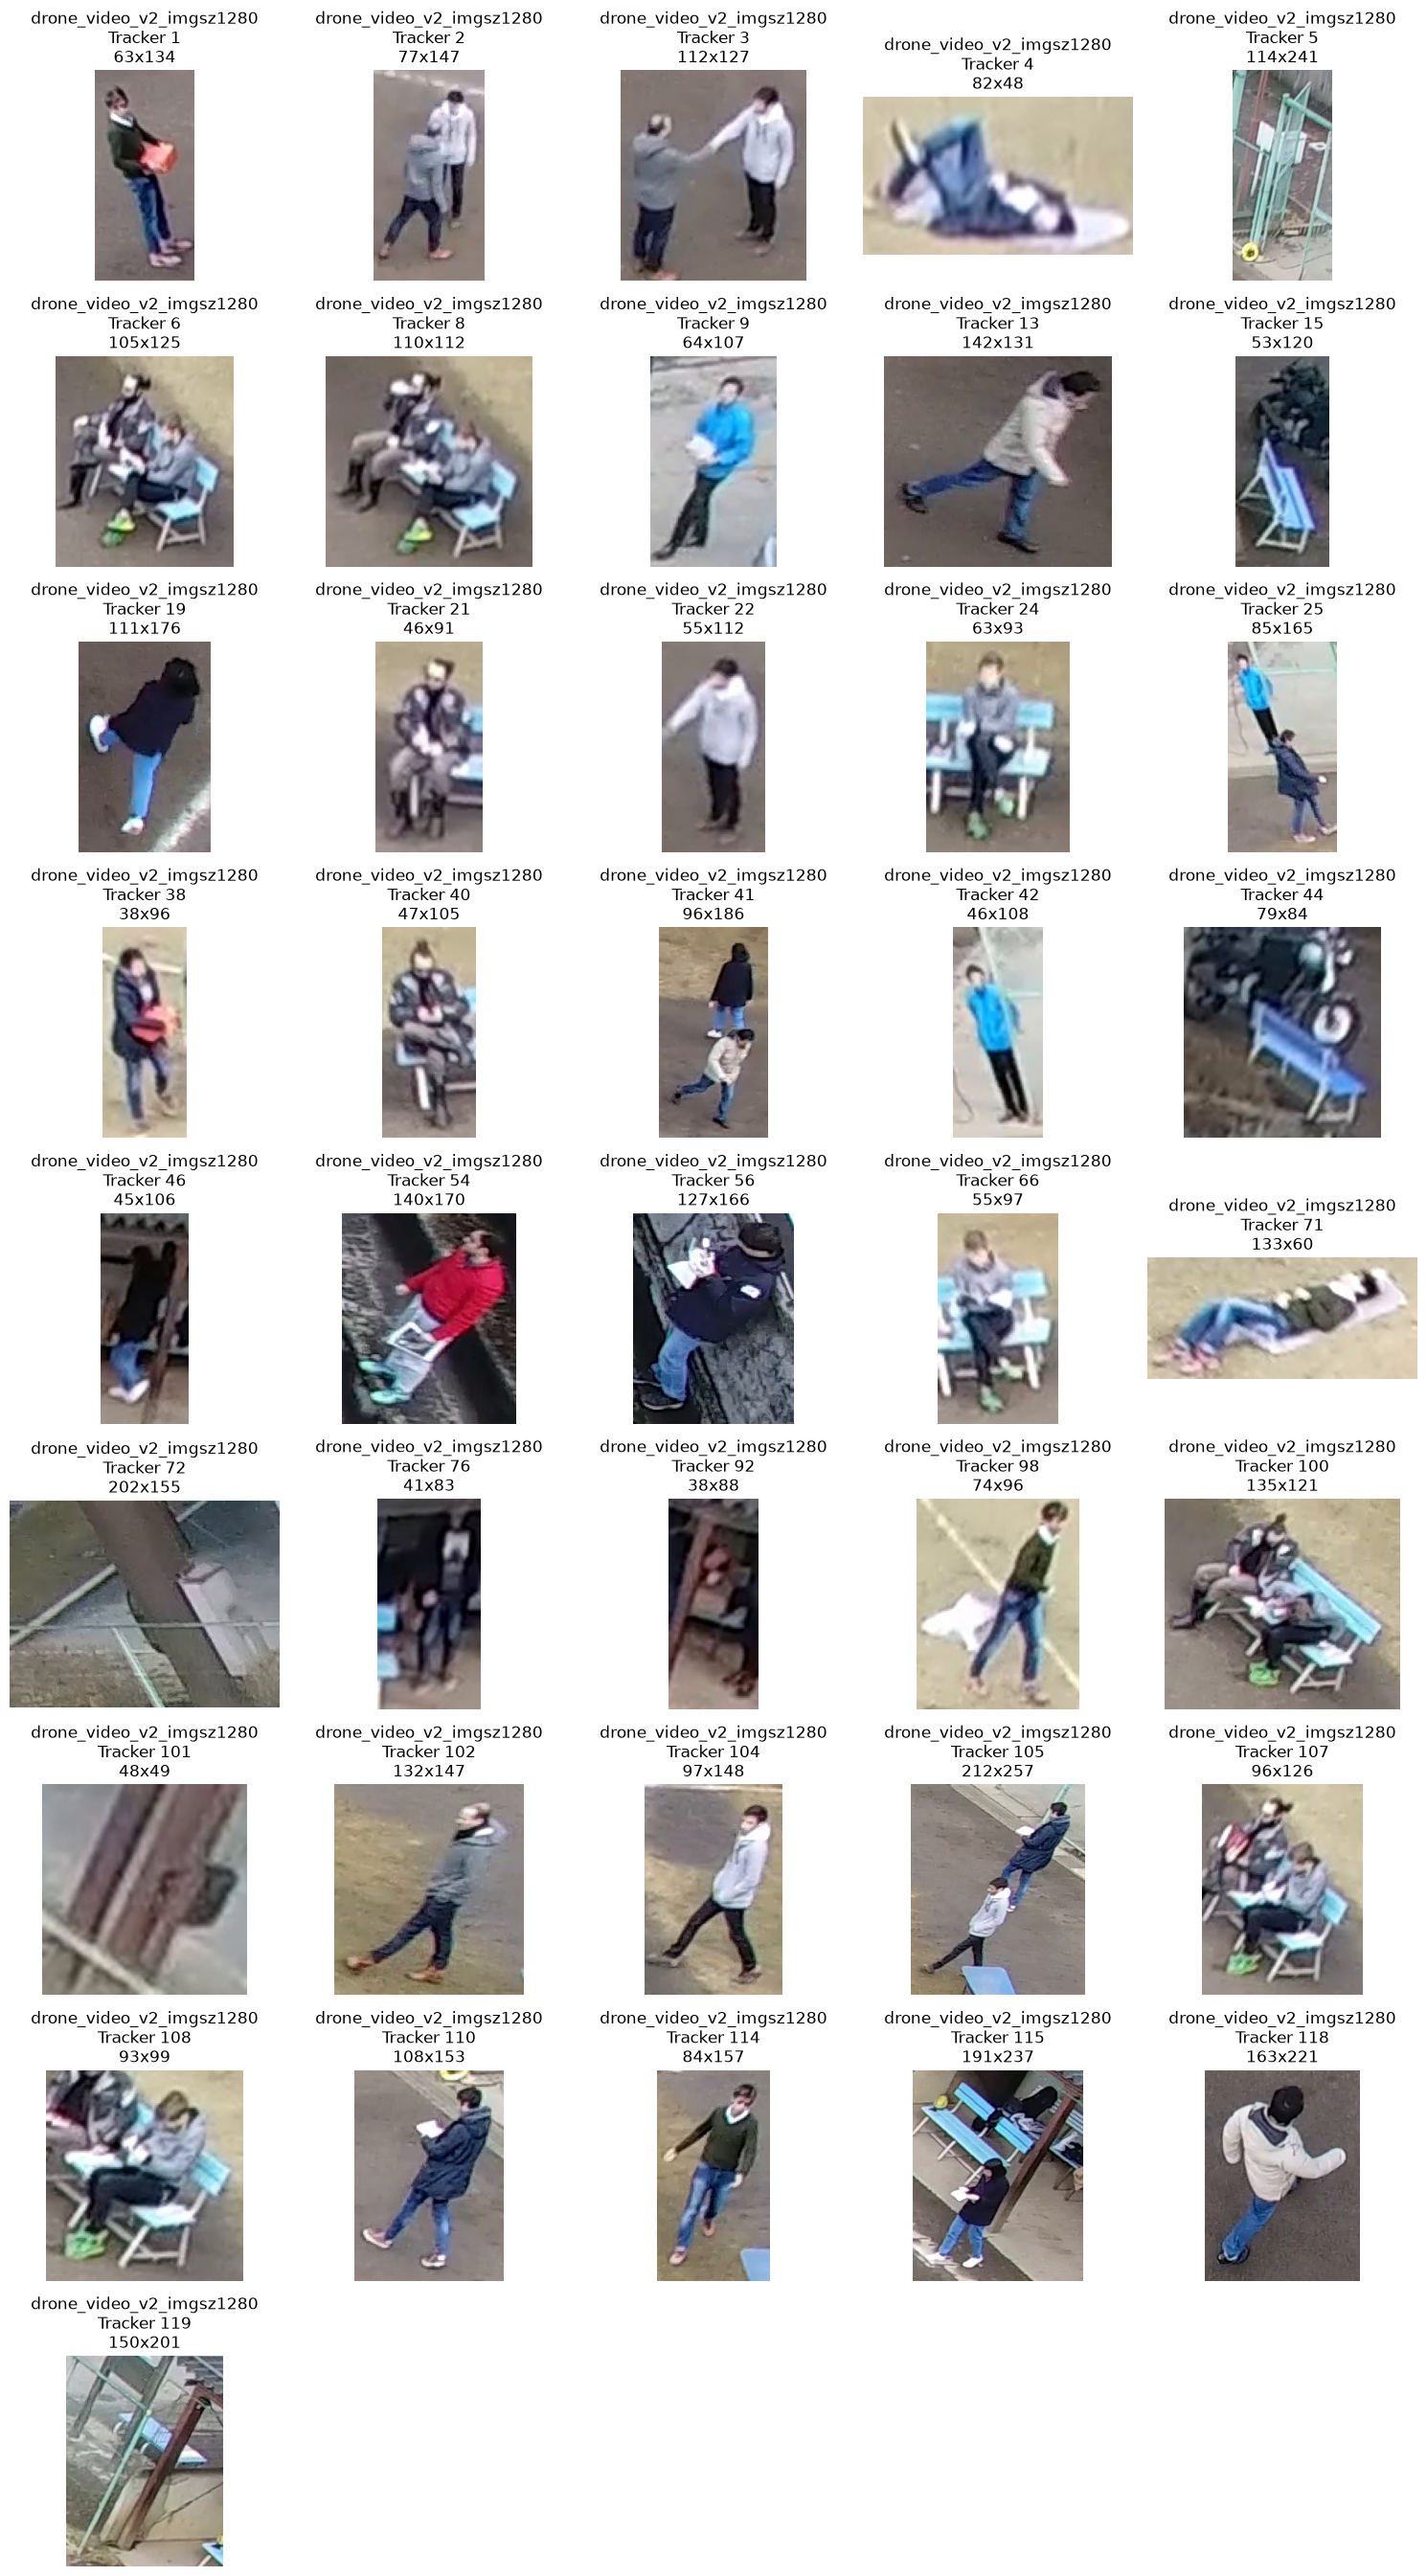

In [6]:
representative_crops = (
    crop_manifest
    .sort_values("quality_score", ascending=False)
    .drop_duplicates("tracklet_key")
    .sort_values(["video_id", "track_id"])
    .reset_index(drop=True)
)

columns = 5
rows = math.ceil(len(representative_crops) / columns)

fig, axes = plt.subplots(
    rows, columns,
    figsize=(columns * 3, rows * 3)
)

axes = np.array(axes).reshape(-1)

for ax in axes:
    ax.axis("off")

for index, row in representative_crops.iterrows():
    image = cv2.imread(row["crop_path"])

    if image is None:
        continue

    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    axes[index].imshow(image)
    axes[index].set_title(
        f"{row['video_id']}\n"
        f"Tracker {int(row['track_id'])}\n"
        f"{row['box_width']}x{row['box_height']}"
    )
    axes[index].axis("off")

plt.tight_layout()
plt.show()

## Section 7 — Extract OSNet embeddings

Use the same pretrained OSNet model as Parts 3, 5 and 6. Each crop gets one 512-dimensional embedding.

In [7]:
reid_model = ReIDModel.from_pretrained(
    REID_MODEL_NAME,
    device=REID_DEVICE
)

crop_paths = crop_manifest["crop_path"].tolist()

embedding_start = time.time()

crop_embeddings = reid_model.extract_embeddings_from_paths(
    crop_paths,
    batch_size=EMBEDDING_BATCH_SIZE,
    num_workers=0
)

crop_embeddings = np.asarray(crop_embeddings, dtype=np.float32)

if crop_embeddings.ndim != 2:
    raise ValueError(f"Unexpected embedding shape: {crop_embeddings.shape}")

if crop_embeddings.shape[0] != len(crop_manifest):
    raise ValueError("Number of embeddings does not match number of crops.")

if not np.isfinite(crop_embeddings).all():
    raise ValueError("OSNet returned non-finite embeddings.")

norms = np.linalg.norm(crop_embeddings, axis=1, keepdims=True)
crop_embeddings = crop_embeddings / np.maximum(norms, 1e-12)

embedding_seconds = time.time() - embedding_start
crop_manifest = crop_manifest.reset_index(drop=True)
crop_manifest["embedding_index"] = np.arange(len(crop_manifest))

print("Embedding matrix:", crop_embeddings.shape)
print("Embedding dimensions:", crop_embeddings.shape[1])
print("Embedding time:", round(embedding_seconds, 2), "seconds")

C:\Users\anyan\AppData\Local\Temp\ipykernel_35848\346117563.py:1: UserWarning: The osnet_x1_0_msmt17_combineall weights were trained on MSMT17 pedestrian images. Performance may degrade significantly on non-person objects (vehicles, animals, products, etc.). Pass a domain-specific checkpoint via `ReIDModel.from_pretrained(source, architecture=...)` for other use cases.
  reid_model = ReIDModel.from_pretrained(


Embedding matrix: (316, 512)
Embedding dimensions: 512
Embedding time: 8.35 seconds


## Section 8 — Build a multi-shot mean prototype per tracklet

For every tracklet:
- Normalize its crop embeddings.
- Average the multiple crop embeddings.
- Normalize the average again.

This mean vector is the primary representation because multi-mean had the strongest pairwise ROC AUC and pairwise average precision in Part 6.

We also retain the individual crop vectors so that multi-max similarity can be reported as a secondary diagnostic.

In [8]:
tracklet_keys = sorted(
    crop_manifest["tracklet_key"].astype(str).unique().tolist()
)

tracklet_vectors = []
tracklet_shot_vectors = {}
tracklet_meta = {}

for key in tracklet_keys:
    group = crop_manifest[
        crop_manifest["tracklet_key"] == key
    ].sort_values("quality_score", ascending=False)

    indices = group["embedding_index"].astype(int).to_numpy()
    shots = crop_embeddings[indices]

    mean_vector = shots.mean(axis=0)
    mean_norm = np.linalg.norm(mean_vector)
    mean_vector = mean_vector / max(float(mean_norm), 1e-12)

    tracklet_vectors.append(mean_vector)
    tracklet_shot_vectors[key] = shots

    # Use full track-log intervals, not only the selected crop frames.
    full_track = track_log[
        track_log["tracklet_key"] == key
    ]

    first = full_track.iloc[0]

    tracklet_meta[key] = {
        "video_id": str(first["video_id"]),
        "track_id": int(first["track_id"]),
        "first_frame": int(full_track["frame"].min()),
        "last_frame": int(full_track["frame"].max()),
        "first_seen": float(full_track["time_seconds"].min()),
        "last_seen": float(full_track["time_seconds"].max()),
        "crop_count": len(group),
        "mean_confidence": float(group["confidence"].mean()),
        "source_order": int(first["source_order"])
    }

tracklet_vectors = np.vstack(tracklet_vectors).astype(np.float32)
vector_index = {
    key: index for index, key in enumerate(tracklet_keys)
}

print("Tracklet feature matrix:", tracklet_vectors.shape)
print("Tracklets represented:", len(tracklet_keys))

tracklet_summary = pd.DataFrame([
    {
        "tracklet_key": key,
        **tracklet_meta[key]
    }
    for key in tracklet_keys
])

display(tracklet_summary.head(20))

Tracklet feature matrix: (41, 512)
Tracklets represented: 41


,tracklet_key,video_id,track_id,first_frame,last_frame,first_seen,last_seen,crop_count,mean_confidence,source_order
0,drone_video_v2_imgsz1280::track_1,drone_video_v2_imgsz1280,1,1,522,0.033367,17.417400,8,0.736792,0
1,drone_video_v2_imgsz1280::track_100,drone_video_v2_imgsz1280,100,1721,1789,57.424033,59.692967,8,0.471220,0
2,drone_video_v2_imgsz1280::track_101,drone_video_v2_imgsz1280,101,1752,1760,58.458400,58.725333,4,0.308390,0
3,drone_video_v2_imgsz1280::track_102,drone_video_v2_imgsz1280,102,1859,2250,62.028633,75.075000,8,0.771324,0
4,drone_video_v2_imgsz1280::track_104,drone_video_v2_imgsz1280,104,1870,2250,62.395667,75.075000,8,0.786635,0
5,drone_video_v2_imgsz1280::track_105,drone_video_v2_imgsz1280,105,1873,1896,62.495767,63.263200,8,0.584471,0
6,drone_video_v2_imgsz1280::track_107,drone_video_v2_imgsz1280,107,1878,2250,62.662600,75.075000,8,0.470599,0
7,drone_video_v2_imgsz1280::track_108,drone_video_v2_imgsz1280,108,1880,1926,62.729333,64.264200,8,0.311990,0
8,drone_video_v2_imgsz1280::track_110,drone_video_v2_imgsz1280,110,1890,2250,63.063000,75.075000,8,0.793764,0
9,drone_video_v2_imgsz1280::track_114,drone_video_v2_imgsz1280,114,1929,2250,64.364300,75.075000,8,0.737851,0


## Section 9 — Generate same-video tracklet similarity candidates

Primary score:
- `multi_mean_similarity`: cosine similarity between the two tracklet mean prototypes.

Secondary diagnostic:
- `multi_max_similarity`: maximum similarity between any retained crop from tracklet A and any retained crop from tracklet B.

Compatibility rule:
- Both tracklets must belong to the active video.
- Their full observed frame intervals must not overlap. This allows a person who disappears and later returns with a new BoT-SORT ID to become a candidate match.
- Cross-video matching is disabled in this single-video workflow.

In [9]:
HAS_WORLD = {"world_x", "world_y", "world_h"}.issubset(track_log.columns)
if USE_SPATIAL_GATING and not HAS_WORLD:
    print("WARNING: no world coordinates in the tracking log (rerun fixed Part 1). "
          "Using appearance only.")
USE_SPATIAL_GATING = USE_SPATIAL_GATING and HAS_WORLD
motion_table = (
    U.build_tracklet_motion_table(track_log, cfg=SPATIAL_CFG)
    if USE_SPATIAL_GATING else {}
)
spatial_rejections = {}

candidate_rows = []
scores_by_key = {key: [] for key in tracklet_keys}

for i, key_a in enumerate(tracklet_keys):
    meta_a = tracklet_meta[key_a]

    for j in range(i + 1, len(tracklet_keys)):
        key_b = tracklet_keys[j]
        meta_b = tracklet_meta[key_b]

        same_video = meta_a["video_id"] == meta_b["video_id"]

        if not same_video and not ENABLE_CROSS_VIDEO_MATCHING:
            continue

        if same_video:
            intervals_overlap = not (
                meta_a["last_frame"] < meta_b["first_frame"] or
                meta_b["last_frame"] < meta_a["first_frame"]
            )

            if intervals_overlap:
                continue

            if meta_a["last_frame"] < meta_b["first_frame"]:
                gap_frames = (
                    meta_b["first_frame"] - meta_a["last_frame"] - 1
                )
            else:
                gap_frames = (
                    meta_a["first_frame"] - meta_b["last_frame"] - 1
                )

            fps = video_metadata[meta_a["video_id"]]["fps"]
            gap_seconds = max(0, gap_frames) / fps
        else:
            gap_frames = np.nan
            gap_seconds = np.nan

        appearance_similarity = float(
            tracklet_vectors[vector_index[key_a]] @
            tracklet_vectors[vector_index[key_b]]
        )
        mean_similarity = appearance_similarity
        spatial_bonus = 0.0
        world_distance = np.nan
        world_allowed = np.nan
        spatial_reason = "not_used"

        if (same_video and USE_SPATIAL_GATING
                and key_a in motion_table and key_b in motion_table):
            spatial = U.spatial_compatibility(
                motion_table[key_a], motion_table[key_b], fps, SPATIAL_CFG
            )
            if spatial["rejected"]:
                spatial_rejections[spatial["reason"]] = (
                    spatial_rejections.get(spatial["reason"], 0) + 1
                )
                continue
            mean_similarity, spatial_bonus = U.fuse_similarity(
                appearance_similarity, spatial, SPATIAL_CFG
            )
            world_distance = spatial["distance"]
            world_allowed = spatial["allowed"]
            spatial_reason = spatial["reason"]

        # Secondary multi-max score across all crop pairs.
        shot_similarity_matrix = (
            tracklet_shot_vectors[key_a] @
            tracklet_shot_vectors[key_b].T
        )
        max_similarity = float(shot_similarity_matrix.max())

        candidate_rows.append({
            "tracklet_a": key_a,
            "tracklet_b": key_b,
            "video_a": meta_a["video_id"],
            "video_b": meta_b["video_id"],
            "same_video": same_video,
            "gap_frames": gap_frames,
            "gap_seconds": gap_seconds,
            "multi_mean_similarity": mean_similarity,
            "multi_max_similarity": max_similarity,
            "appearance_similarity": appearance_similarity,
            "spatial_bonus": spatial_bonus,
            "world_distance": world_distance,
            "world_allowed": world_allowed,
            "spatial_reason": spatial_reason
        })

        scores_by_key[key_a].append((mean_similarity, key_b))
        scores_by_key[key_b].append((mean_similarity, key_a))

candidate_columns = [
    "tracklet_a", "tracklet_b", "video_a", "video_b", "same_video",
    "gap_frames", "gap_seconds", "multi_mean_similarity",
    "multi_max_similarity", "appearance_similarity", "spatial_bonus",
    "world_distance", "world_allowed", "spatial_reason",
    "rank_for_a", "rank_for_b",
    "margin_for_a", "margin_for_b", "mutual_best", "initial_decision"
]
candidate_df = pd.DataFrame(candidate_rows, columns=candidate_columns)

if candidate_df.empty:
    print("No compatible pairs were found.")
else:
    candidate_df = candidate_df.sort_values(
        "multi_mean_similarity",
        ascending=False
    ).reset_index(drop=True)

print("Compatible tracklet pairs:", len(candidate_df))
print("Pairs rejected as spatially impossible:", spatial_rejections)

if not candidate_df.empty:
    display(candidate_df.head(30))

Compatible tracklet pairs: 159
Pairs rejected as spatially impossible: {'height_mismatch': 430, 'too_far': 53}


,tracklet_a,tracklet_b,video_a,video_b,same_video,gap_frames,gap_seconds,multi_mean_similarity,multi_max_similarity,appearance_similarity,spatial_bonus,world_distance,world_allowed,spatial_reason,rank_for_a,rank_for_b,margin_for_a,margin_for_b,mutual_best,initial_decision
0,drone_video_v2_imgsz1280::track_24,drone_video_v2_imgsz1280::track_66,drone_video_v2_imgsz1280,drone_video_v2_imgsz1280,True,216,7.207200,0.999181,0.911317,0.971270,0.027911,19.691784,416.635473,ok,NaN,NaN,NaN,NaN,NaN,NaN
1,drone_video_v2_imgsz1280::track_21,drone_video_v2_imgsz1280::track_40,drone_video_v2_imgsz1280,drone_video_v2_imgsz1280,True,33,1.101100,0.989928,0.894444,0.918903,0.071025,2.398135,113.326857,ok,NaN,NaN,NaN,NaN,NaN,NaN
2,drone_video_v2_imgsz1280::track_6,drone_video_v2_imgsz1280::track_8,drone_video_v2_imgsz1280,drone_video_v2_imgsz1280,True,80,2.669333,0.983714,0.903849,0.931710,0.052003,8.810089,768.077765,ok,NaN,NaN,NaN,NaN,NaN,NaN
3,drone_video_v2_imgsz1280::track_42,drone_video_v2_imgsz1280::track_9,drone_video_v2_imgsz1280,drone_video_v2_imgsz1280,True,37,1.234567,0.929582,0.838405,0.868143,0.061438,16.026732,127.242204,ok,NaN,NaN,NaN,NaN,NaN,NaN
4,drone_video_v2_imgsz1280::track_107,drone_video_v2_imgsz1280::track_6,drone_video_v2_imgsz1280,drone_video_v2_imgsz1280,True,1793,59.826433,0.918584,0.890773,0.918584,0.000000,NaN,NaN,long_gap_no_spatial_evidence,NaN,NaN,NaN,NaN,NaN,NaN
5,drone_video_v2_imgsz1280::track_15,drone_video_v2_imgsz1280::track_44,drone_video_v2_imgsz1280,drone_video_v2_imgsz1280,True,137,4.571233,0.908980,0.847536,0.873844,0.035136,41.924635,383.416512,ok,NaN,NaN,NaN,NaN,NaN,NaN
6,drone_video_v2_imgsz1280::track_19,drone_video_v2_imgsz1280::track_41,drone_video_v2_imgsz1280,drone_video_v2_imgsz1280,True,50,1.668333,0.906878,0.857928,0.864898,0.041980,69.169790,202.203394,ok,NaN,NaN,NaN,NaN,NaN,NaN
7,drone_video_v2_imgsz1280::track_100,drone_video_v2_imgsz1280::track_108,drone_video_v2_imgsz1280,drone_video_v2_imgsz1280,True,90,3.003000,0.888170,0.794441,0.839674,0.048496,28.277935,1168.342194,ok,NaN,NaN,NaN,NaN,NaN,NaN
8,drone_video_v2_imgsz1280::track_107,drone_video_v2_imgsz1280::track_8,drone_video_v2_imgsz1280,drone_video_v2_imgsz1280,True,1605,53.553500,0.864979,0.856319,0.864979,0.000000,NaN,NaN,long_gap_no_spatial_evidence,NaN,NaN,NaN,NaN,NaN,NaN
9,drone_video_v2_imgsz1280::track_108,drone_video_v2_imgsz1280::track_8,drone_video_v2_imgsz1280,drone_video_v2_imgsz1280,True,1607,53.620233,0.853269,0.836256,0.853269,0.000000,NaN,NaN,long_gap_no_spatial_evidence,NaN,NaN,NaN,NaN,NaN,NaN


## Section 10 — Apply mutual-best and margin checks

For each tracklet, rank its compatible candidates by multi-mean similarity.

A high proposal is created only when:
1. The pair's multi-mean score is at least `AUTO_LINK_THRESHOLD`.
2. A is B's best candidate.
3. B is A's best candidate.
4. Both best-versus-second-best margins are at least `MIN_SIMILARITY_MARGIN`.

Pairs between `REVIEW_THRESHOLD` and `AUTO_LINK_THRESHOLD` are sent to the review queue.

This is a provisional decision rule. It has not been separately calibrated on your own drone recordings.

In [10]:
ranked_candidates = {
    key: sorted(items, key=lambda item: item[0], reverse=True)
    for key, items in scores_by_key.items()
}

best_candidate = {}
best_score_by_key = {}
margin_by_key = {}

for key, ranked in ranked_candidates.items():
    if not ranked:
        best_candidate[key] = None
        best_score_by_key[key] = np.nan
        margin_by_key[key] = np.nan
        continue

    best_score, best_key = ranked[0]
    best_candidate[key] = best_key
    best_score_by_key[key] = float(best_score)

    if len(ranked) >= 2:
        margin_by_key[key] = float(best_score - ranked[1][0])
    else:
        margin_by_key[key] = np.nan

if not candidate_df.empty:
    ranks_a, ranks_b = [], []
    margins_a, margins_b = [], []
    mutual_values, decisions = [], []

    for _, row in candidate_df.iterrows():
        key_a = row["tracklet_a"]
        key_b = row["tracklet_b"]

        rank_a = next(
            index + 1
            for index, item in enumerate(ranked_candidates[key_a])
            if item[1] == key_b
        )
        rank_b = next(
            index + 1
            for index, item in enumerate(ranked_candidates[key_b])
            if item[1] == key_a
        )

        margin_a = margin_by_key[key_a]
        margin_b = margin_by_key[key_b]

        mutual = (
            best_candidate[key_a] == key_b and
            best_candidate[key_b] == key_a
        )

        margin_ok = (
            np.isfinite(margin_a) and
            np.isfinite(margin_b) and
            margin_a >= MIN_SIMILARITY_MARGIN and
            margin_b >= MIN_SIMILARITY_MARGIN
        )

        score = float(row["multi_mean_similarity"])

        if (
            score >= AUTO_LINK_THRESHOLD and
            mutual and margin_ok
        ):
            decision = "high_similarity_proposal"
        elif score >= REVIEW_THRESHOLD:
            decision = "review_required"
        else:
            decision = "low_similarity"

        ranks_a.append(rank_a)
        ranks_b.append(rank_b)
        margins_a.append(margin_a)
        margins_b.append(margin_b)
        mutual_values.append(mutual)
        decisions.append(decision)

    candidate_df["rank_for_a"] = ranks_a
    candidate_df["rank_for_b"] = ranks_b
    candidate_df["margin_for_a"] = margins_a
    candidate_df["margin_for_b"] = margins_b
    candidate_df["mutual_best"] = mutual_values
    candidate_df["initial_decision"] = decisions

    candidate_df = candidate_df.sort_values(
        "multi_mean_similarity",
        ascending=False
    ).reset_index(drop=True)

print("Candidate decision counts:")
if not candidate_df.empty:
    display(
        candidate_df["initial_decision"]
        .value_counts()
        .rename_axis("decision")
        .reset_index(name="pairs")
    )
    display(candidate_df.head(30))

# Keep the expected columns even when there are no compatible pairs.
# This lets Parts 9 and 10 load an empty candidate CSV safely.
for column, dtype in [
    ("rank_for_a", "float64"),
    ("rank_for_b", "float64"),
    ("margin_for_a", "float64"),
    ("margin_for_b", "float64"),
    ("mutual_best", "bool"),
    ("initial_decision", "object")
]:
    if column not in candidate_df.columns:
        candidate_df[column] = pd.Series(dtype=dtype)


Candidate decision counts:


,decision,pairs
0,low_similarity,123
1,review_required,27
2,high_similarity_proposal,9


,tracklet_a,tracklet_b,video_a,video_b,same_video,gap_frames,gap_seconds,multi_mean_similarity,multi_max_similarity,appearance_similarity,spatial_bonus,world_distance,world_allowed,spatial_reason,rank_for_a,rank_for_b,margin_for_a,margin_for_b,mutual_best,initial_decision
0,drone_video_v2_imgsz1280::track_24,drone_video_v2_imgsz1280::track_66,drone_video_v2_imgsz1280,drone_video_v2_imgsz1280,True,216,7.207200,0.999181,0.911317,0.971270,0.027911,19.691784,416.635473,ok,1,1,0.438777,0.331646,True,high_similarity_proposal
1,drone_video_v2_imgsz1280::track_21,drone_video_v2_imgsz1280::track_40,drone_video_v2_imgsz1280,drone_video_v2_imgsz1280,True,33,1.101100,0.989928,0.894444,0.918903,0.071025,2.398135,113.326857,ok,1,1,0.147304,0.537356,True,high_similarity_proposal
2,drone_video_v2_imgsz1280::track_6,drone_video_v2_imgsz1280::track_8,drone_video_v2_imgsz1280,drone_video_v2_imgsz1280,True,80,2.669333,0.983714,0.903849,0.931710,0.052003,8.810089,768.077765,ok,1,1,0.065130,0.118735,True,high_similarity_proposal
3,drone_video_v2_imgsz1280::track_42,drone_video_v2_imgsz1280::track_9,drone_video_v2_imgsz1280,drone_video_v2_imgsz1280,True,37,1.234567,0.929582,0.838405,0.868143,0.061438,16.026732,127.242204,ok,1,1,0.490946,0.365062,True,high_similarity_proposal
4,drone_video_v2_imgsz1280::track_107,drone_video_v2_imgsz1280::track_6,drone_video_v2_imgsz1280,drone_video_v2_imgsz1280,True,1793,59.826433,0.918584,0.890773,0.918584,0.000000,NaN,NaN,long_gap_no_spatial_evidence,1,2,0.053605,0.065130,False,review_required
5,drone_video_v2_imgsz1280::track_15,drone_video_v2_imgsz1280::track_44,drone_video_v2_imgsz1280,drone_video_v2_imgsz1280,True,137,4.571233,0.908980,0.847536,0.873844,0.035136,41.924635,383.416512,ok,1,1,0.181955,0.242016,True,high_similarity_proposal
6,drone_video_v2_imgsz1280::track_19,drone_video_v2_imgsz1280::track_41,drone_video_v2_imgsz1280,drone_video_v2_imgsz1280,True,50,1.668333,0.906878,0.857928,0.864898,0.041980,69.169790,202.203394,ok,1,1,0.250384,0.198237,True,high_similarity_proposal
7,drone_video_v2_imgsz1280::track_100,drone_video_v2_imgsz1280::track_108,drone_video_v2_imgsz1280,drone_video_v2_imgsz1280,True,90,3.003000,0.888170,0.794441,0.839674,0.048496,28.277935,1168.342194,ok,1,1,0.056142,0.034901,True,high_similarity_proposal
8,drone_video_v2_imgsz1280::track_107,drone_video_v2_imgsz1280::track_8,drone_video_v2_imgsz1280,drone_video_v2_imgsz1280,True,1605,53.553500,0.864979,0.856319,0.864979,0.000000,NaN,NaN,long_gap_no_spatial_evidence,2,2,0.053605,0.118735,False,review_required
9,drone_video_v2_imgsz1280::track_108,drone_video_v2_imgsz1280::track_8,drone_video_v2_imgsz1280,drone_video_v2_imgsz1280,True,1607,53.620233,0.853269,0.836256,0.853269,0.000000,NaN,NaN,long_gap_no_spatial_evidence,2,3,0.034901,0.118735,False,review_required


## Section 11 — Create provisional global identity groups

Tracklets that pass the high-similarity, mutual-best and margin checks are provisionally merged, subject to a same-video overlap constraint.

Every unmerged tracklet receives its own Global ID. Tracklets without enough usable crops also receive a separate provisional ID and are marked as `insufficient_reid_crops`.

Global IDs are not verified real-world identities. They are the current prototype's proposed groups.

In [11]:
all_tracklet_keys = sorted(
    track_log["tracklet_key"].astype(str).unique().tolist()
)

parent = {key: key for key in all_tracklet_keys}
cluster_members = {key: {key} for key in all_tracklet_keys}

def find_root(key):
    while parent[key] != key:
        parent[key] = parent[parent[key]]
        key = parent[key]
    return key

def clusters_can_merge(members_a, members_b):
    for key_a in members_a:
        if key_a not in tracklet_meta:
            continue

        meta_a = tracklet_meta[key_a]

        for key_b in members_b:
            if key_b not in tracklet_meta:
                continue

            meta_b = tracklet_meta[key_b]

            if meta_a["video_id"] != meta_b["video_id"]:
                continue

            overlap = not (
                meta_a["last_frame"] < meta_b["first_frame"] or
                meta_b["last_frame"] < meta_a["first_frame"]
            )

            if overlap:
                return False

    return True

def merge_clusters(key_a, key_b):
    root_a = find_root(key_a)
    root_b = find_root(key_b)

    if root_a == root_b:
        return True

    members_a = cluster_members[root_a]
    members_b = cluster_members[root_b]

    if not clusters_can_merge(members_a, members_b):
        return False

    if len(members_a) < len(members_b):
        root_a, root_b = root_b, root_a
        members_a, members_b = members_b, members_a

    parent[root_b] = root_a
    cluster_members[root_a] = members_a.union(members_b)
    del cluster_members[root_b]

    return True

merge_log = {}

if (
    ENABLE_PROVISIONAL_AUTO_LINKS and
    not candidate_df.empty
):
    high_proposals = candidate_df[
        candidate_df["initial_decision"] == "high_similarity_proposal"
    ].sort_values("multi_mean_similarity", ascending=False)

    for _, row in high_proposals.iterrows():
        pair = (row["tracklet_a"], row["tracklet_b"])
        accepted = merge_clusters(*pair)

        merge_log[pair] = (
            "provisional_link_created"
            if accepted
            else "rejected_same_video_overlap_conflict"
        )

# Order IDs by video source order and first frame.
def tracklet_sort_key(key):
    rows = track_log[track_log["tracklet_key"] == key]
    first = rows.iloc[0]

    return (
        int(first["source_order"]),
        int(rows["frame"].min()),
        key
    )

ordered_tracklet_keys = sorted(all_tracklet_keys, key=tracklet_sort_key)

root_to_global_id = {}

for key in ordered_tracklet_keys:
    root = find_root(key)

    if root not in root_to_global_id:
        root_to_global_id[root] = f"G{len(root_to_global_id) + 1:04d}"

global_id_by_tracklet = {
    key: root_to_global_id[find_root(key)]
    for key in all_tracklet_keys
}

cluster_size_by_tracklet = {
    key: len(cluster_members[find_root(key)])
    for key in all_tracklet_keys
}

print("All local tracklets:", len(all_tracklet_keys))
print("Tracklets with OSNet embeddings:", len(tracklet_keys))
print(
    "Provisional global identity groups:",
    len(set(global_id_by_tracklet.values()))
)
print(
    "Tracklets in merged groups:",
    sum(size > 1 for size in cluster_size_by_tracklet.values())
)
print("High-similarity proposals considered:", len(merge_log))

All local tracklets: 41
Tracklets with OSNet embeddings: 41
Provisional global identity groups: 32
Tracklets in merged groups: 18
High-similarity proposals considered: 9


## Section 12 — Export candidate matches and global identity registry

The registry contains one row per local tracklet. It includes the global ID, video ID, local tracker ID, observation interval, best candidate, similarity score and match status.

The candidate file also records the primary multi-mean score and the secondary multi-max score.

In [12]:
# Map selected representative crop paths for each tracklet.
representative_path_by_key = (
    crop_manifest
    .sort_values("quality_score", ascending=False)
    .drop_duplicates("tracklet_key")
    .set_index("tracklet_key")["crop_path"]
    .to_dict()
)

registry_rows = []

for key in ordered_tracklet_keys:
    rows = track_log[track_log["tracklet_key"] == key]
    first = rows.iloc[0]

    if key in tracklet_meta:
        meta = tracklet_meta[key]
        best_key = best_candidate.get(key)
        best_score = best_score_by_key.get(key, np.nan)

        if cluster_size_by_tracklet[key] > 1:
            status = "provisional_auto_link"
        elif best_key is not None and best_score >= REVIEW_THRESHOLD:
            status = "review_required"
        else:
            status = "unmatched_tracklet"

        crop_count = meta["crop_count"]
    else:
        meta = {
            "first_frame": int(rows["frame"].min()),
            "last_frame": int(rows["frame"].max()),
            "first_seen": float(rows["time_seconds"].min()),
            "last_seen": float(rows["time_seconds"].max())
        }
        best_key = None
        best_score = np.nan
        status = "insufficient_reid_crops"
        crop_count = 0

    registry_rows.append({
        "global_id": global_id_by_tracklet[key],
        "tracklet_key": key,
        "video_id": str(first["video_id"]),
        "track_id": int(first["track_id"]),
        "first_frame": int(rows["frame"].min()),
        "last_frame": int(rows["frame"].max()),
        "first_seen_seconds": float(rows["time_seconds"].min()),
        "last_seen_seconds": float(rows["time_seconds"].max()),
        "crop_count": int(crop_count),
        "best_candidate_tracklet": best_key or "",
        "best_candidate_similarity": best_score,
        "match_status": status,
        "identity_verified": False
    })

global_registry = pd.DataFrame(registry_rows)

REGISTRY_PATH = PART7_DIR / "global_identity_registry.csv"
global_registry.to_csv(REGISTRY_PATH, index=False)

if not candidate_df.empty:
    candidate_df["global_id_a"] = candidate_df["tracklet_a"].map(
        global_id_by_tracklet
    )
    candidate_df["global_id_b"] = candidate_df["tracklet_b"].map(
        global_id_by_tracklet
    )
    candidate_df["cluster_decision"] = [
        merge_log.get(
            (row["tracklet_a"], row["tracklet_b"]),
            "not_auto_linked"
        )
        for _, row in candidate_df.iterrows()
    ]

CANDIDATES_PATH = PART7_DIR / "candidate_matches.csv"
candidate_df.to_csv(CANDIDATES_PATH, index=False)

REVIEW_PATH = PART7_DIR / "manual_review_queue.csv"

if not candidate_df.empty:
    review_queue = candidate_df[
        candidate_df["multi_mean_similarity"] >= REVIEW_THRESHOLD
    ].copy()
else:
    review_queue = candidate_df.head(0).copy()

review_queue["manual_label"] = ""
review_queue["review_notes"] = ""

review_queue.to_csv(REVIEW_PATH, index=False)

print("Registry:", REGISTRY_PATH)
print("Candidate matches:", CANDIDATES_PATH)
print("Manual review queue:", REVIEW_PATH)

print("\nRegistry summary:")
display(
    global_registry["match_status"]
    .value_counts()
    .rename_axis("status")
    .reset_index(name="tracklets")
)

display(global_registry.head(30))

Registry: C:\Users\anyan\Desktop\AeroTrack_clude\outputs\drone_video_v2_imgsz1280\part7_global_identity\global_identity_registry.csv
Candidate matches: C:\Users\anyan\Desktop\AeroTrack_clude\outputs\drone_video_v2_imgsz1280\part7_global_identity\candidate_matches.csv
Manual review queue: C:\Users\anyan\Desktop\AeroTrack_clude\outputs\drone_video_v2_imgsz1280\part7_global_identity\manual_review_queue.csv

Registry summary:


,status,tracklets
0,provisional_auto_link,18
1,unmatched_tracklet,13
2,review_required,10


,global_id,tracklet_key,video_id,track_id,first_frame,last_frame,first_seen_seconds,last_seen_seconds,crop_count,best_candidate_tracklet,best_candidate_similarity,match_status,identity_verified
0,G0001,drone_video_v2_imgsz1280::track_1,drone_video_v2_imgsz1280,1,1,522,0.033367,17.417400,8,drone_video_v2_imgsz1280::track_98,0.766557,review_required,False
1,G0002,drone_video_v2_imgsz1280::track_2,drone_video_v2_imgsz1280,2,1,953,0.033367,31.798433,8,drone_video_v2_imgsz1280::track_76,0.468358,unmatched_tracklet,False
2,G0003,drone_video_v2_imgsz1280::track_3,drone_video_v2_imgsz1280,3,1,432,0.033367,14.414400,8,drone_video_v2_imgsz1280::track_98,0.570955,unmatched_tracklet,False
3,G0004,drone_video_v2_imgsz1280::track_4,drone_video_v2_imgsz1280,4,1,207,0.033367,6.906900,8,drone_video_v2_imgsz1280::track_38,0.717699,review_required,False
4,G0005,drone_video_v2_imgsz1280::track_5,drone_video_v2_imgsz1280,5,11,101,0.367033,3.370033,8,drone_video_v2_imgsz1280::track_119,0.760019,provisional_auto_link,False
5,G0006,drone_video_v2_imgsz1280::track_6,drone_video_v2_imgsz1280,6,12,84,0.400400,2.802800,8,drone_video_v2_imgsz1280::track_8,0.983714,provisional_auto_link,False
6,G0006,drone_video_v2_imgsz1280::track_8,drone_video_v2_imgsz1280,8,165,272,5.505500,9.075733,8,drone_video_v2_imgsz1280::track_6,0.983714,provisional_auto_link,False
7,G0007,drone_video_v2_imgsz1280::track_9,drone_video_v2_imgsz1280,9,175,519,5.839167,17.317300,8,drone_video_v2_imgsz1280::track_42,0.929582,provisional_auto_link,False
8,G0008,drone_video_v2_imgsz1280::track_13,drone_video_v2_imgsz1280,13,235,1073,7.841167,35.802433,8,drone_video_v2_imgsz1280::track_98,0.691078,review_required,False
9,G0009,drone_video_v2_imgsz1280::track_15,drone_video_v2_imgsz1280,15,288,487,9.609600,16.249567,8,drone_video_v2_imgsz1280::track_44,0.908980,provisional_auto_link,False


## Section 13 — Visualize proposed identity matches

The contact sheet compares the clearest crop from each side of the highest-scoring candidate pairs.

Use it to check whether the proposed match appears plausible. The source video and tracker ID are included in the labels.

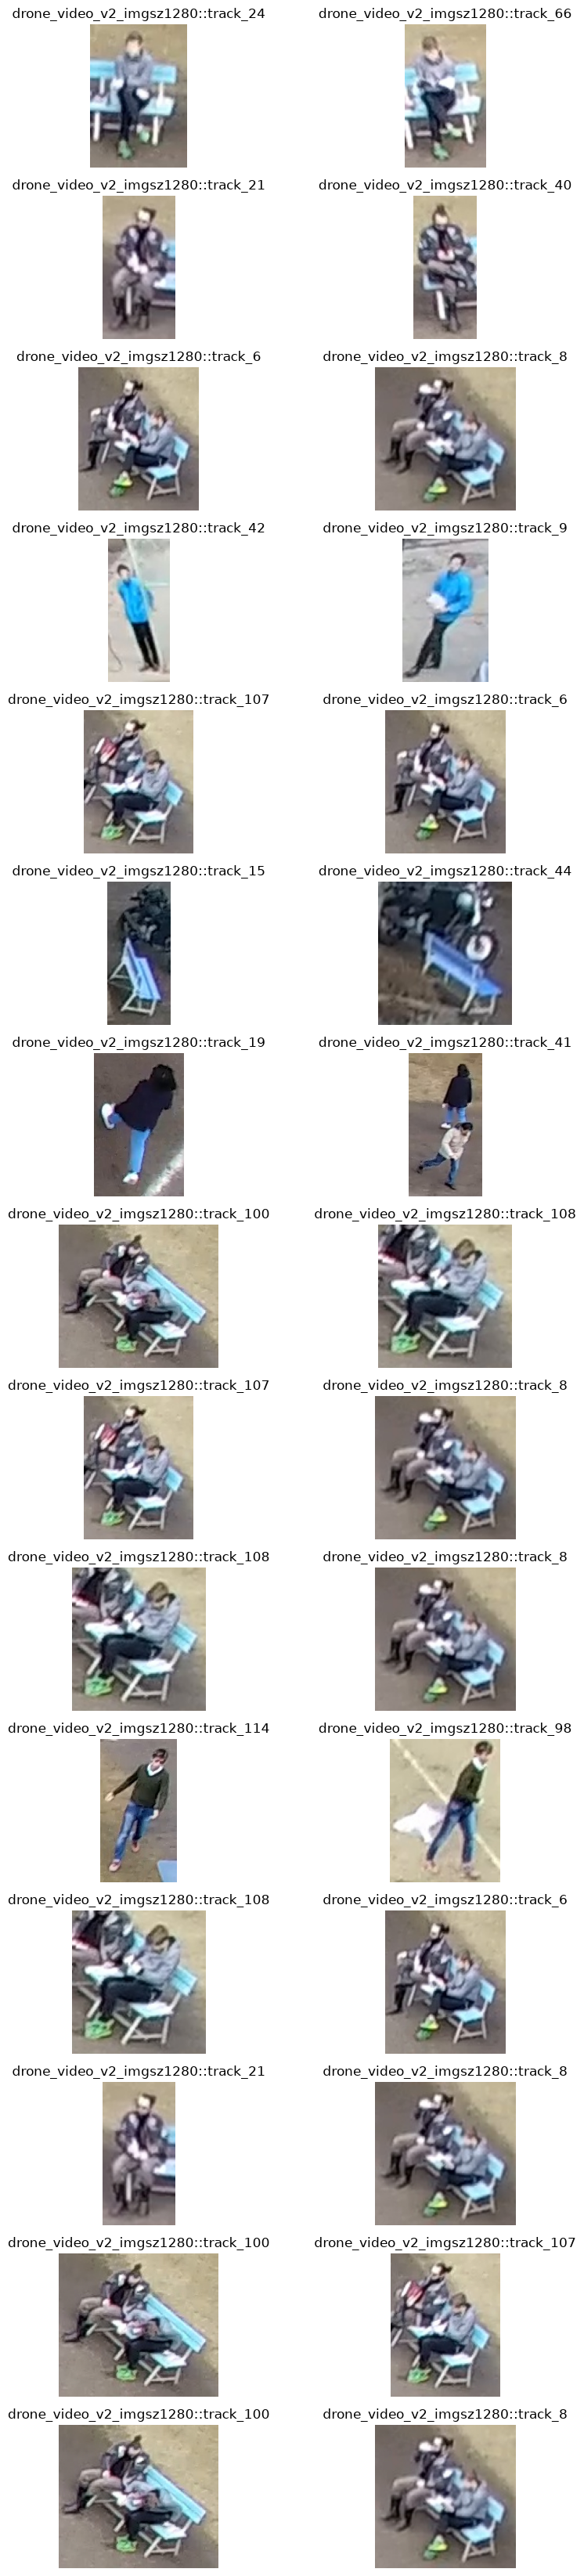

In [13]:
if candidate_df.empty:
    print("No candidate matches to display.")
else:
    top_pairs = candidate_df.head(15)

    fig, axes = plt.subplots(
        len(top_pairs), 2,
        figsize=(10, max(4, len(top_pairs) * 2.2))
    )

    if len(top_pairs) == 1:
        axes = np.array([axes])

    for row_index, (_, pair) in enumerate(top_pairs.iterrows()):
        for col_index, key in enumerate([
            pair["tracklet_a"], pair["tracklet_b"]
        ]):
            ax = axes[row_index, col_index]
            ax.axis("off")

            crop_path = representative_path_by_key.get(key)

            if not crop_path:
                continue

            image = cv2.imread(crop_path)

            if image is None:
                continue

            ax.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
            ax.set_title(key)

        axes[row_index, 0].set_ylabel(
            f"Mean: {pair['multi_mean_similarity']:.3f}\n"
            f"Max: {pair['multi_max_similarity']:.3f}\n"
            f"{pair.get('initial_decision', '')}",
            rotation=0,
            labelpad=100,
            va="center"
        )

    plt.tight_layout()
    plt.show()

## Section 14 — Create annotated video with Global IDs

This is the first visible AeroTrack output.

For the active source video, the notebook:
- Reads the logged video segment.
- Draws the BoT-SORT bounding boxes.
- Displays the provisional Global ID and local tracker ID.
- Writes a new MP4 in the Part 7 output folder.

A Global ID shared by multiple tracklets is marked `PROVISIONAL`. An unmerged tracklet is assigned its own Global ID. This output is a prototype visualization, not a verified count of unique people.

In [14]:
def stable_color(text):
    # Create a repeatable, visible BGR color from an ID string.
    digest = hashlib.md5(text.encode("utf-8")).digest()
    return (
        int(70 + digest[0] % 170),
        int(70 + digest[1] % 170),
        int(70 + digest[2] % 170)
    )


ANNOTATED_PATHS = []

for source in VIDEO_SOURCES:
    video_id = str(source["video_id"])
    meta = video_metadata[video_id]

    video_log = track_log[
        track_log["video_id"] == video_id
    ].copy()

    if video_log.empty:
        continue

    log_by_frame = {
        int(frame_number): group
        for frame_number, group in video_log.groupby("frame")
    }

    max_frame = int(video_log["frame"].max())

    cap = cv2.VideoCapture(str(meta["video_path"]))
    cap.set(
        cv2.CAP_PROP_POS_MSEC,
        meta["segment_start_seconds"] * 1000
    )

    if not cap.isOpened():
        raise RuntimeError(f"{video_id}: could not open video for annotation.")

    output_path = PART7_DIR / f"{video_id}_global_ids.mp4"

    writer = cv2.VideoWriter(
        str(output_path),
        cv2.VideoWriter_fourcc(*"mp4v"),
        meta["fps"],
        (meta["width"], meta["height"])
    )

    if not writer.isOpened():
        cap.release()
        raise RuntimeError(f"Could not create output video: {output_path}")

    frame_number = 0

    while frame_number < max_frame:
        success, frame = cap.read()

        if not success:
            break

        frame_number += 1

        rows = log_by_frame.get(frame_number)

        if rows is not None:
            for _, row in rows.iterrows():
                tracklet_key = row["tracklet_key"]
                global_id = global_id_by_tracklet[tracklet_key]
                track_id = int(row["track_id"])

                x1 = max(0, int(round(row["x1"])))
                y1 = max(0, int(round(row["y1"])))
                x2 = min(meta["width"] - 1, int(round(row["x2"])))
                y2 = min(meta["height"] - 1, int(round(row["y2"])))

                if x2 <= x1 or y2 <= y1:
                    continue

                color = stable_color(global_id)

                cv2.rectangle(
                    frame,
                    (x1, y1),
                    (x2, y2),
                    color,
                    2
                )

                provisional = (
                    cluster_size_by_tracklet[tracklet_key] > 1
                )

                label = (
                    f"{global_id} | T{track_id}"
                    + (" PROV" if provisional else "")
                )

                text_y = max(22, y1 - 7)

                cv2.putText(
                    frame,
                    label,
                    (x1, text_y),
                    cv2.FONT_HERSHEY_SIMPLEX,
                    0.65,
                    color,
                    2,
                    cv2.LINE_AA
                )

        # Video label.
        cv2.putText(
            frame,
            f"AeroTrack | {video_id}",
            (25, 40),
            cv2.FONT_HERSHEY_SIMPLEX,
            1.0,
            (0, 255, 255),
            2,
            cv2.LINE_AA
        )

        writer.write(frame)

    cap.release()
    writer.release()

    ANNOTATED_PATHS.append(output_path)

    print("Saved annotated video:", output_path)

print("Annotated videos created:", len(ANNOTATED_PATHS))

Saved annotated video: C:\Users\anyan\Desktop\AeroTrack_clude\outputs\drone_video_v2_imgsz1280\part7_global_identity\drone_video_v2_imgsz1280_global_ids.mp4
Annotated videos created: 1


## Section 15 — Final prototype summary

The number of provisional global IDs is **not** a verified unique-person count. It is the number of groups produced by the current matching rules, including unmerged tracklets assigned separate IDs.

Review the outputs before using this figure as an actual population count.

In [15]:
provisional_global_id_count = global_registry["global_id"].nunique()

multi_tracklet_groups = (
    global_registry.groupby("global_id")
    .agg(
        tracklets=("tracklet_key", "count"),
        videos=("video_id", "nunique"),
        video_ids=("video_id", lambda values: ", ".join(sorted(set(values))))
    )
    .reset_index()
)

multi_tracklet_groups = multi_tracklet_groups[
    multi_tracklet_groups["tracklets"] > 1
].sort_values("tracklets", ascending=False)

summary = {
    "videos_processed": [str(source["video_id"]) for source in VIDEO_SOURCES],
    "local_tracklets": int(track_log["tracklet_key"].nunique()),
    "tracklets_with_embeddings": int(len(tracklet_keys)),
    "candidate_pairs": int(len(candidate_df)),
    "high_similarity_proposals": int(
        (candidate_df["initial_decision"] == "high_similarity_proposal").sum()
    ) if not candidate_df.empty else 0,
    "review_queue_pairs": int(len(review_queue)),
    "provisional_global_id_groups": int(provisional_global_id_count),
    "multi_tracklet_global_groups": int(len(multi_tracklet_groups)),
    "annotated_videos": [str(path) for path in ANNOTATED_PATHS],
    "primary_similarity": "multi_mean",
    "secondary_similarity": "multi_max",
    "auto_link_threshold": AUTO_LINK_THRESHOLD,
    "review_threshold": REVIEW_THRESHOLD,
    "minimum_similarity_margin": MIN_SIMILARITY_MARGIN,
    "note": (
        "Provisional identity groups are not verified unique people. "
        "Thresholds are experimental and require evaluation on the target videos. "
        "Cross-video matching is not calibrated by the within-sequence VisDrone "
        "validation results."
    )
}

SUMMARY_PATH = PART7_DIR / "global_identity_summary.json"

with open(SUMMARY_PATH, "w", encoding="utf-8") as file:
    json.dump(summary, file, indent=2)

print("GLOBAL IDENTITY SUMMARY")
display(pd.DataFrame([summary]))

print("Groups containing multiple tracklets:")
display(multi_tracklet_groups.head(30))

print("Output folder:", PART7_DIR)

GLOBAL IDENTITY SUMMARY


,videos_processed,local_tracklets,tracklets_with_embeddings,candidate_pairs,high_similarity_proposals,review_queue_pairs,provisional_global_id_groups,multi_tracklet_global_groups,annotated_videos,primary_similarity,secondary_similarity,auto_link_threshold,review_threshold,minimum_similarity_margin,note
0,[drone_video_v2_imgsz1280],41,41,159,9,36,32,9,[C:\Users\anyan\Desktop\AeroTrack_clude\output...,multi_mean,multi_max,0.72,0.65,0.015,Provisional identity groups are not verified u...


Groups containing multiple tracklets:


,global_id,tracklets,videos,video_ids
4,G0005,2,1,drone_video_v2_imgsz1280
5,G0006,2,1,drone_video_v2_imgsz1280
6,G0007,2,1,drone_video_v2_imgsz1280
8,G0009,2,1,drone_video_v2_imgsz1280
9,G0010,2,1,drone_video_v2_imgsz1280
10,G0011,2,1,drone_video_v2_imgsz1280
12,G0013,2,1,drone_video_v2_imgsz1280
22,G0023,2,1,drone_video_v2_imgsz1280
23,G0024,2,1,drone_video_v2_imgsz1280


Output folder: C:\Users\anyan\Desktop\AeroTrack_clude\outputs\drone_video_v2_imgsz1280\part7_global_identity


## Section 16 — Play one annotated result

Choose one of the generated annotated videos and review the labels. `Gxxxx` is the provisional Global ID; `Txx` is the original local BoT-SORT tracker ID. `PROV` marks a Global ID currently shared by more than one tracklet.

In [16]:
if ANNOTATED_PATHS:
    selected_video = ANNOTATED_PATHS[0]
    print("Playing:", selected_video)
    display(Video(str(selected_video), embed=False, width=1000))
else:
    print("No annotated video was generated.")

Playing: C:\Users\anyan\Desktop\AeroTrack_clude\outputs\drone_video_v2_imgsz1280\part7_global_identity\drone_video_v2_imgsz1280_global_ids.mp4


## Section 17 — What to send back

Please provide:

1. The final summary table from Section 15.
2. The groups containing multiple tracklets from Section 15.
3. The top 20 rows of `candidate_matches.csv`.
4. A screenshot or short clip from the annotated video showing Global IDs.
5. The crop gallery if you see incorrect, empty or mismatched person crops.

Files saved in `outputs/<video_id>/part7_global_identity/`:
- `crop_manifest.csv`
- `global_identity_registry.csv`
- `candidate_matches.csv`
- `manual_review_queue.csv`
- `<video_id>_global_ids.mp4`
- `global_identity_summary.json`

## Part 7 conclusion

This notebook generates OSNet multi-shot appearance features and compares non-overlapping tracklets within the active video. The result is a provisional identity grouping, not proof of identity. Inspect the crop pairs and annotated video before trusting the Global ID count.